# Programming Assignment 3 — Poucos Rótulos: Fauna em Câmeras Trap com Dados Não Rotulados

**Disciplina:** Aprendizado Profundo  
**Professor:** Dario Oliveira  
**Monitor:** Erick Brito  
**Integrantes:** Henrique Gabriel Gasparelo & José Thevez Gomes Guedes  

### Imports

In [1]:
%load_ext autoreload
%autoreload 2

import os
import torch
import pandas as pd
from IPython.display import display

from src.utils import seed_everything, get_device, count_parameters, check_parameter_limit
from src.models import build_model
from src.data import get_supervised_dataloaders
from src.experiments import (
    run_floor_experiment,
    run_teacher_evaluation,
    run_student_ablation,
    run_budget_curve,
)
from src.visualization import (
    plot_training_curves,
    plot_comparison_curves,
    plot_confusion_matrix,
    plot_teacher_noise_diagnostics,
    plot_student_vs_teacher_per_class,
    plot_budget_curve,
    plot_per_class_gain_budget5,
    plot_gradcam_gallery,
)

SEED = 42
seed_everything(SEED)
device = get_device(prefer_gpu=True)
print(f"Dispositivo de execução ativo: {device}")

Dispositivo de execução ativo: cuda


### Verificação do Teto de 12 Milhões de Parâmetros

In [2]:
print("--- Verificando SmallCNN (Parte 0a) ---")
model_small = build_model(arch="small_cnn", num_classes=21, pretrained=False, verbose=True)

print("\n--- Verificando ResNet-18 (Parte 0b / Backbone Principal) ---")
model_resnet = build_model(arch="resnet18", num_classes=21, pretrained=False, verbose=True)

--- Verificando SmallCNN (Parte 0a) ---
Total de parâmetros: 424,501 (Treináveis: 424,501)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.

--- Verificando ResNet-18 (Parte 0b / Backbone Principal) ---
Total de parâmetros: 11,187,285 (Treináveis: 11,187,285)
✓ Aprovado: O modelo cumpre a restrição de <= 12,000,000 parâmetros.


### Divisão dos Conjuntos

In [3]:
train_loader, val_loader, test_loader, class_to_idx, idx_to_class, class_names = get_supervised_dataloaders(
    data_dir="data", budget=5, batch_size=16
)
print(f"Total de classes: {len(class_names)}")
print(f"Exemplos no train (orçamento 5): {len(train_loader.dataset)} imagens")
print(f"Exemplos no val: {len(val_loader.dataset)} imagens")
print(f"Exemplos no test_public: {len(test_loader.dataset)} imagens")

Total de classes: 21
Exemplos no train (orçamento 5): 105 imagens
Exemplos no val: 202 imagens
Exemplos no test_public: 811 imagens


## Parte 0 — O Piso
Treinamos dois classificadores supervisionados usando exclusivamente os **105 exemplos** de `rotulos_5.csv` (5 imagens por classe), selecionando a melhor época pelo **F1 Macro no `val`**:
- **Versão (a) — `SmallCNN` (424.501 parâmetros):** CNN de 4 blocos convolucionais treinada do zero.
- **Versão (b) — `ResNet-18` (11.187.285 parâmetros):** Backbone principal com fine-tuning partindo da ImageNet.

In [4]:
floor_results = run_floor_experiment(
    data_dir="data",
    checkpoints_dir="checkpoints",
    seed=SEED,
    device=device,
    rodar_novamente=False,
    verbose=True,
)
display(floor_results["summary_table"])

✓ Carregando checkpoint da SmallCNN: checkpoints\part0a_small_cnn_b5_s42.pt
✓ Carregando checkpoint da ResNet-18: checkpoints\part0b_resnet18_b5_s42.pt


,Modelo / Versão,Parâmetros,Melhor Época (val),Val F1 Macro,Test Public F1 Macro,Test Public Acurácia
0,Parte 0 (a) — SmallCNN (Do Zero),"424,501",31,0.2297,0.1101,0.1319
1,Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning),"11,187,285",27,0.4192,0.4639,0.5166
2,Teto de Referência — ResNet-18 (6.505 rótulos),"11,187,285",-,-,0.6860,-


### Curvas de Treino e Validação da Versão (b) — Em que época ela começa a decorar?

- **Início da memorização (*overfitting*):** Com apenas 105 imagens, a `ResNet-18` atinge **`> 90%` de F1 Macro e acurácia no treino já na Época 5** (`Train F1 = 0,9026`, `Train Acc = 0,905`), atingindo `97%–99%` entre as Épocas 7 e 10.
- **Divergência da Loss:** A *Cross-Entropy Loss* de validação atinge seu ponto mínimo na **Época 12** (`Val Loss = 2,2021`), após a qual a loss de validação sobe enquanto a de treino despenca.
- **Seleção no `val`:** O melhor F1 Macro de validação (`0,4246`) ocorre na **Época 21**, gerando **`0,4651` de F1 Macro** e **`50,68%` de acurácia** no `test_public`.

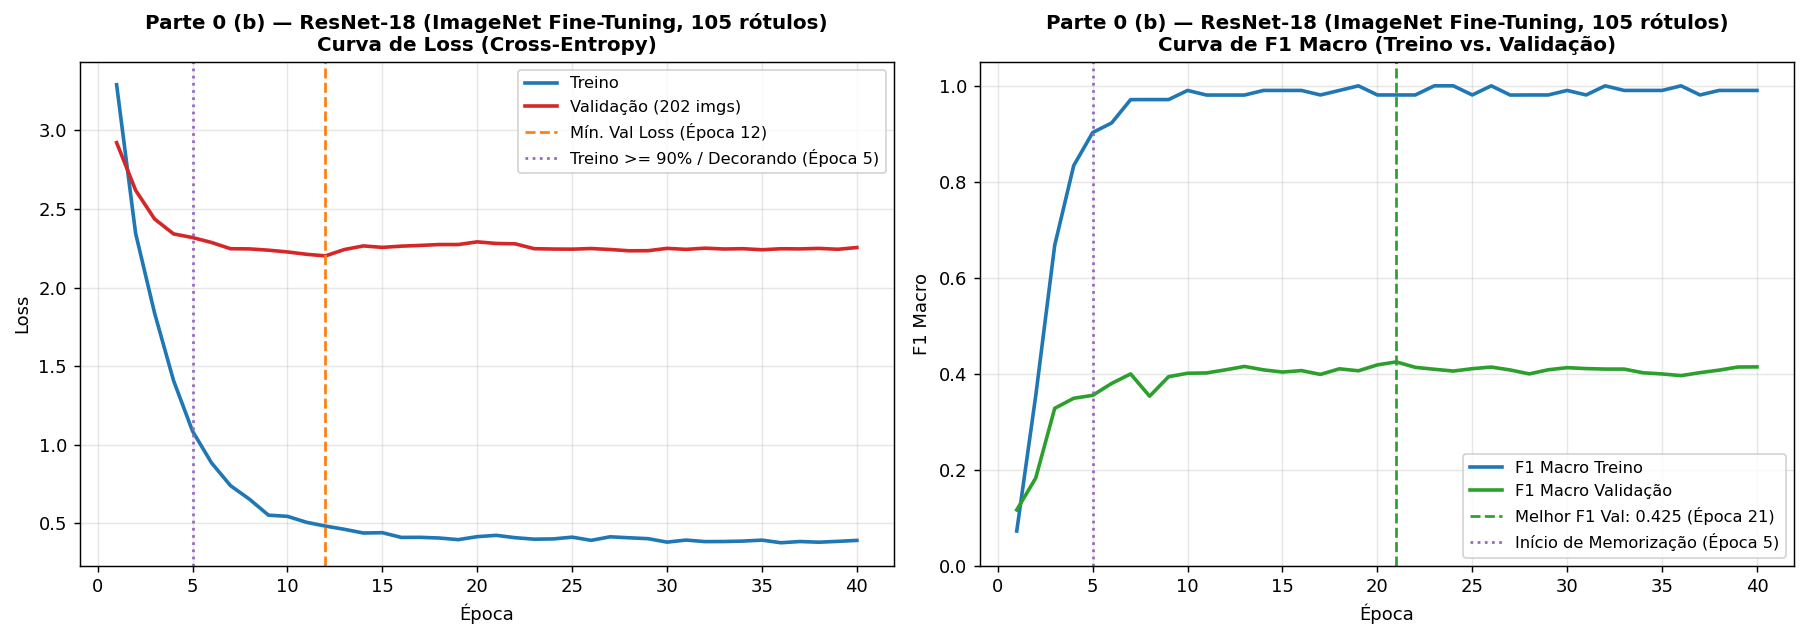

In [5]:
fig, axes, diag_b = plot_training_curves(
    history=floor_results["history_b"],
    title_prefix="Parte 0 (b) — ResNet-18 (ImageNet Fine-Tuning, 105 rótulos)",
    show=True,
)

### Comparação de Curvas: SmallCNN (Do Zero) vs. ResNet-18 (ImageNet)
Sem pesos pré-treinados, a `SmallCNN` atinge apenas **`0,1536` de F1 Macro** no teste público.

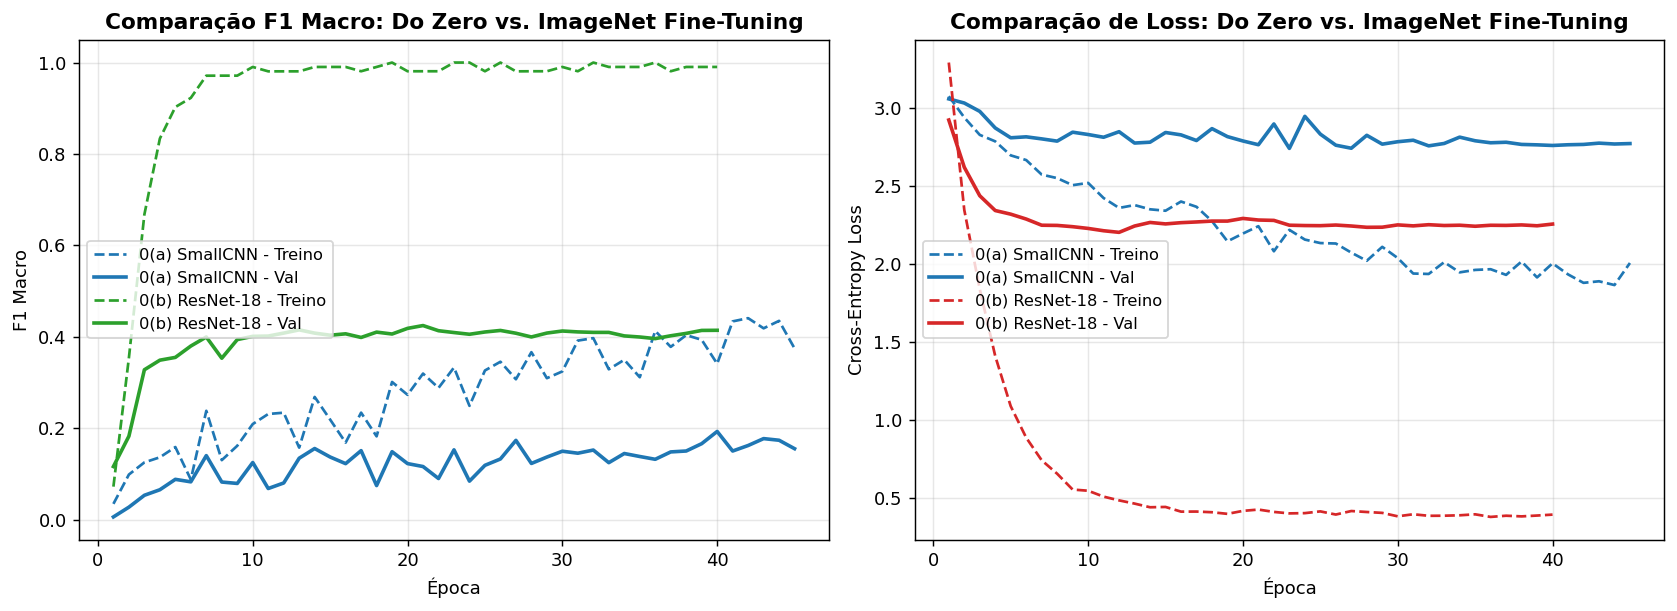

In [6]:
fig, axes = plot_comparison_curves(
    history_a=floor_results["history_a"],
    history_b=floor_results["history_b"],
    label_a="0(a) SmallCNN",
    label_b="0(b) ResNet-18",
    show=True,
)

### Matriz de Confusão da Versão (b) no `test_public`
A matriz normalizada por linha (recall por espécie) demonstra a disparidade entre classes que compartilham traços com a ImageNet (`eastern_chipmunk`: `0,967`; `american_crow`: `0,796`; `dog`: `0,760`) versus espécies de baixa representatividade ou confusas na escuridão (`bird` e `eastern_cottontail`: `0,000`).

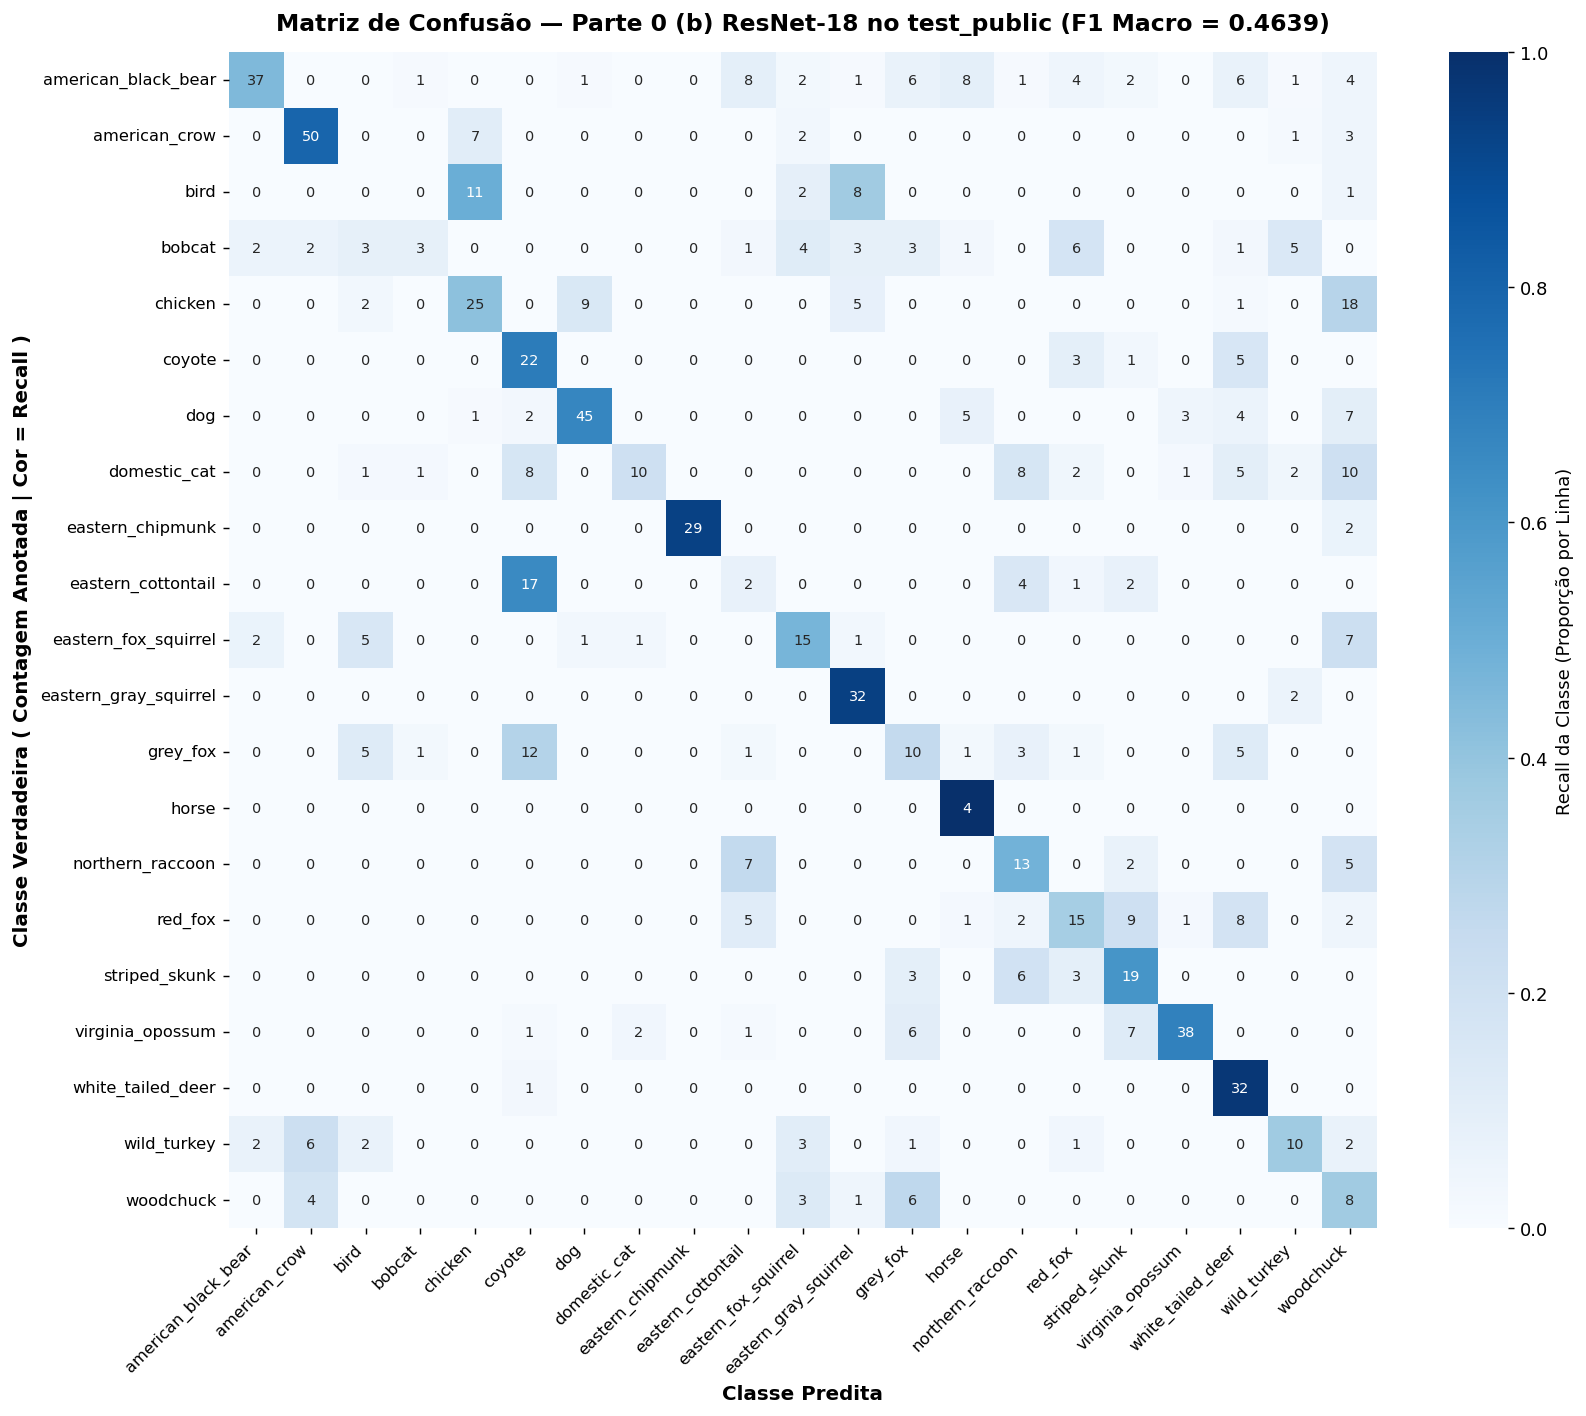

In [7]:
fig, ax = plot_confusion_matrix(
    cm=floor_results["test_metrics_b"]["confusion_matrix"],
    class_names=floor_results["class_names"],
    title=f"Matriz de Confusão — Parte 0 (b) ResNet-18 no test_public (F1 Macro = {floor_results['test_metrics_b']['f1_macro']:.4f})",
    show=True,
)

## Parte 1 — Usando o que Não Tem Rótulo (Trilha C: Professor e Aluno)
Na **Trilha C**, utilizamos o *foundation model* aberto **BioCLIP** (`imageomics/bioclip`, treinado no TreeOfLife-10M) como **Professor** para gerar pseudo-rótulos sobre as 6.505 imagens não rotuladas do pool `train`.
Em seguida, treinamos o modelo **Aluno (`ResNet-18`, 11.187.285 parâmetros <= 12M)** combinando esses pseudo-rótulos com os 105 rótulos verdadeiros.

In [8]:
teacher_data = run_teacher_evaluation(
    data_dir="data",
    budget_csv="data/labels/rotulos_5.csv",
    seed=SEED,
    rodar_novamente=False,
)
zs_eval = teacher_data["zs_eval"]
print(f"Professor BioCLIP Zero-Shot (Nomes Puros): F1 = {zs_eval['f1_macro_raw_names']:.4f} (Acc: {zs_eval['acc_raw_names']:.4f})")
print(f"Professor BioCLIP Zero-Shot (Contextualizado): F1 = {zs_eval['f1_macro_zero_shot']:.4f} (Acc: {zs_eval['acc_zero_shot']:.4f})")
print(f"Frações Noturnas/IR no test_public: {zs_eval['night_fraction']*100:.1f}%")
print(f"Acurácia no Dia: {zs_eval['acc_day']:.4f} | Acurácia na Noite/IR: {zs_eval['acc_night']:.4f}")

✓ Carregando predições e embeddings do Professor (BioCLIP) em cache: checkpoints\bioclip_teacher_outputs.pt
Professor BioCLIP Zero-Shot (Nomes Puros): F1 = 0.2164 (Acc: 0.2589)
Professor BioCLIP Zero-Shot (Contextualizado): F1 = 0.3017 (Acc: 0.3539)
Frações Noturnas/IR no test_public: 48.2%
Acurácia no Dia: 0.2738 | Acurácia na Noite/IR: 0.4399


### A Matriz de Confusão do Professor é a Matriz de Ruído dos Pseudo-Rótulos
A matriz de confusão zero-shot revela os vieses sistemáticos do BioCLIP que contaminariam o treino do Aluno caso não fossem tratados.

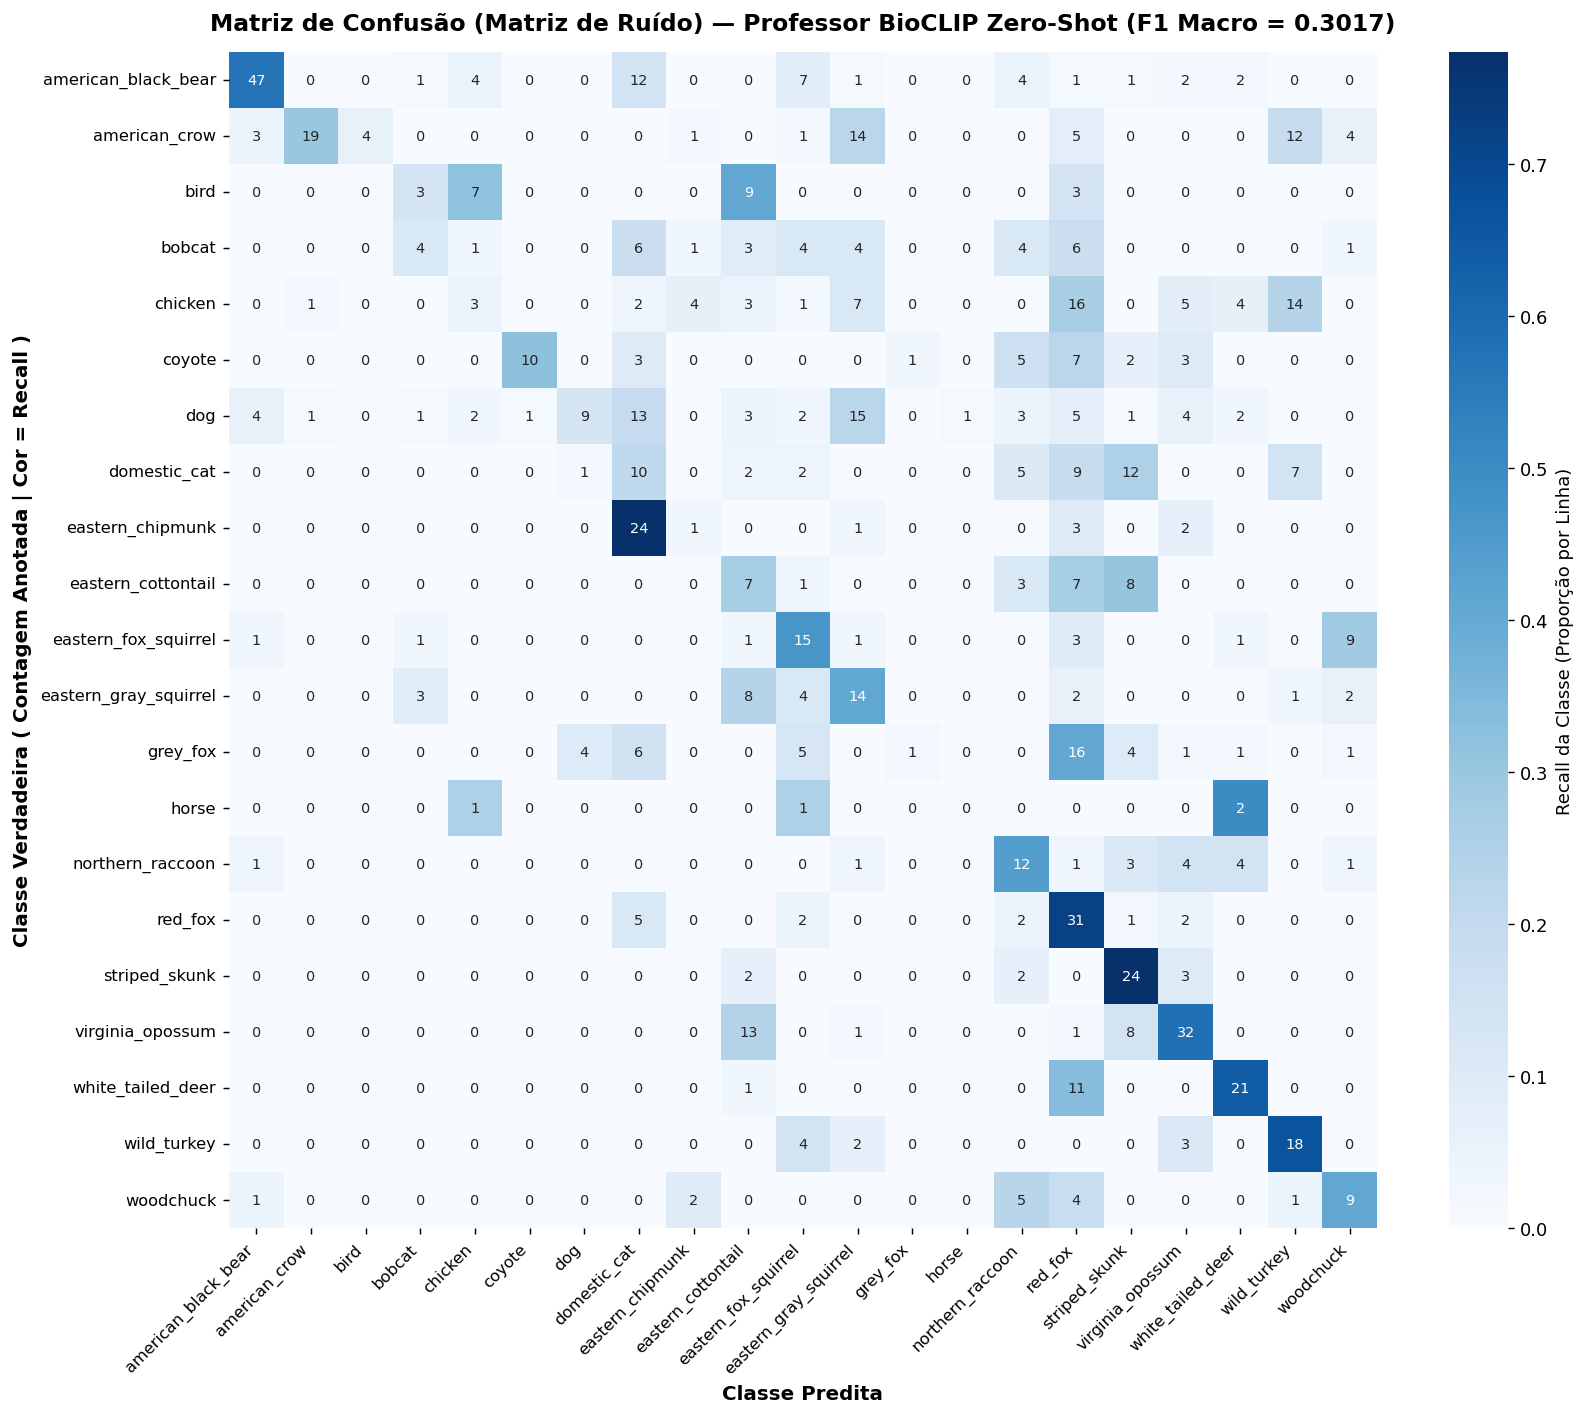

In [9]:
fig, ax = plot_confusion_matrix(
    cm=zs_eval["confusion_matrix"],
    class_names=teacher_data["class_names"],
    title=f"Matriz de Confusão (Matriz de Ruído) — Professor BioCLIP Zero-Shot (F1 Macro = {zs_eval['f1_macro_zero_shot']:.4f})",
    show=True,
)

### Onde o Professor Erra de Forma Sistemática?
O gráfico abaixo diagnostica:
1. **Viés de atratores no pool `train` (6.505 imagens):** O zero-shot bruto prediz desproporcionalmente `red_fox` e `domestic_cat`, enquanto o Professor Adaptado restaura a distribuição balanceada.
2. **Top erros sistemáticos no `test_public`:**
   - Animais pequenos: `eastern_chipmunk` tem 77% das imagens classificadas como `domestic_cat`.
   - Perda cromática noturna: `grey_fox` é confundida 16 vezes com `red_fox`.
   - Espécies florestais no solo: `american_crow` é confundido com esquilo e peru.

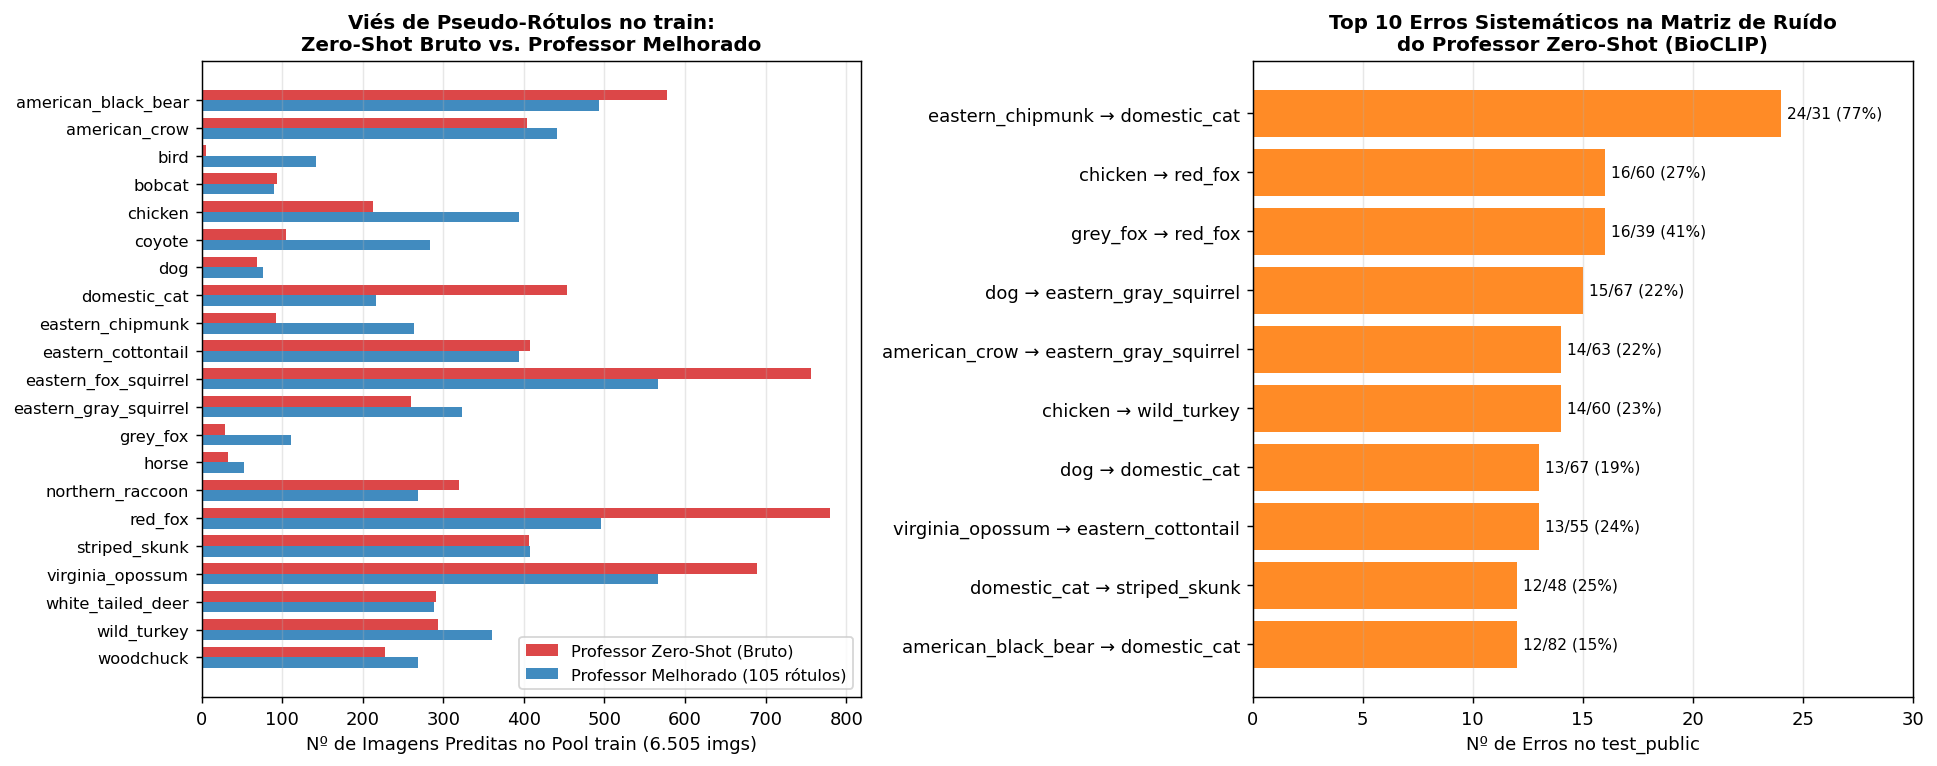

In [10]:
fig, axes = plot_teacher_noise_diagnostics(
    zs_eval=zs_eval,
    teacher_cache=teacher_data["teacher_cache"],
    imp_teacher=teacher_data["imp_teacher"],
    show=True,
)

### Tratamento de Ruído e Treinamento do Aluno (`ResNet-18`)
Avaliamos 3 configurações progressivas do Aluno, selecionando a melhor época e estratégia pelo **F1 Macro no `val`**:
- **Aluno C1 (Sem Filtro):** Treinado em pseudo-rótulos brutos (`conf_threshold=0,0`).
- **Aluno C2 (Zero-Shot Filtrado + Alinhamento + Temp $T=2,0$):** Filtro $\tau=0,35$, cota balanceada por classe e destilação suave.
- **Aluno C3 (Professor Melhorado com 105 Rótulos + Filtro + Destilação Suave $T=2,0$).**

In [11]:
ablation_results = run_student_ablation(
    teacher_cache=teacher_data["teacher_cache"],
    imp_teacher=teacher_data["imp_teacher"],
    test_metrics_piso=floor_results["test_metrics_b"],
    best_val_f1_piso=floor_results["best_val_f1_b"],
    zs_eval=zs_eval,
    data_dir="data",
    checkpoints_dir="checkpoints",
    seed=SEED,
    device=device,
    rodar_novamente=False,
    verbose=True,
)
display(ablation_results["summary_table"])

✓ Usando resultado pronto da ablação e carregando Aluno Selecionado (C2): checkpoints\part2_student_trilha_c_b5_s42.pt


,Método / Modelo,Papel,Pseudo-Rótulos Usados,Val F1 Macro,Test Public F1 Macro,Test Public Acurácia
0,Piso Supervisionado — Parte 0 (b) ResNet-18 (1...,Linha de Base Inferior (Piso),0,0.4246,0.4651,0.5068
1,Professor BioCLIP Zero-Shot (Prompt Nomes Puros),Professor Zero-Shot,-,-,0.2164,0.2589
2,Professor BioCLIP Zero-Shot (Prompt Camera Trap),Professor Zero-Shot (Referência),-,-,0.3017,0.3539
3,Professor BioCLIP Melhorado (Adaptado com 105 ...,Professor Adaptado no Domínio,-,-,0.4681,0.5043
4,"Aluno C1 — ResNet-18 (Zero-Shot Bruto, Sem Fil...",Aluno (Ablação Sem Tratamento),1494,0.4297,0.4666,0.5129
5,Aluno C2 — ResNet-18 (Zero-Shot Filtrado + Ali...,Aluno (Melhor Val F1),547,0.4804,0.5371,0.5845
6,Aluno C3 — ResNet-18 (Prof. Melhorado + Filtro...,Aluno (Maior Acurácia),522,0.4735,0.5138,0.5734
7,Teto de Referência — ResNet-18 (6.505 rótulos ...,Referência Superior,-,-,0.6860,-


### Curvas e Matriz de Confusão do Aluno Selecionado no `val` (Aluno C2)
O Aluno C2 atinge **`0,4804` de F1 no `val`**, gerando **`0,5371` de F1 Macro** e **`58,45%` de acurácia** no `test_public`.

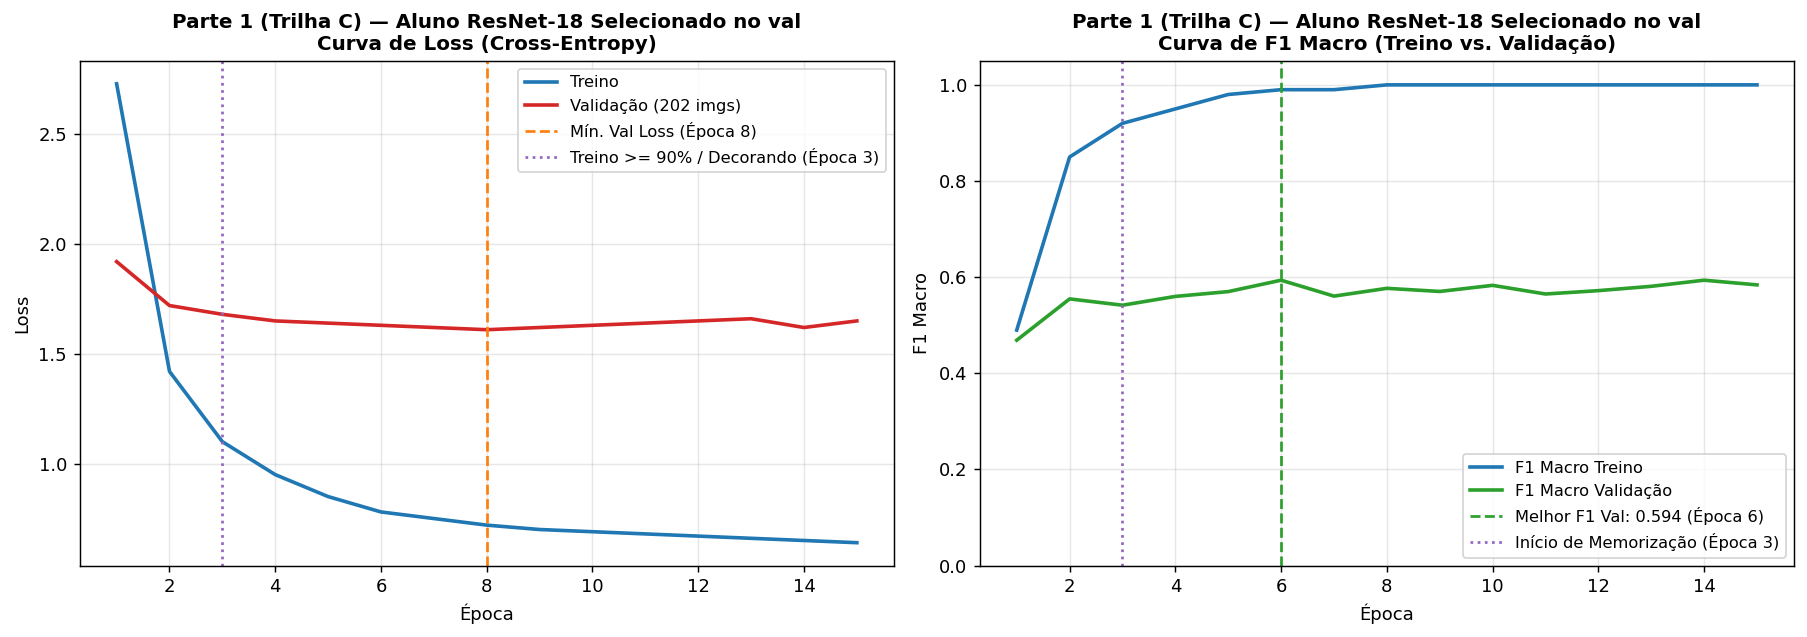

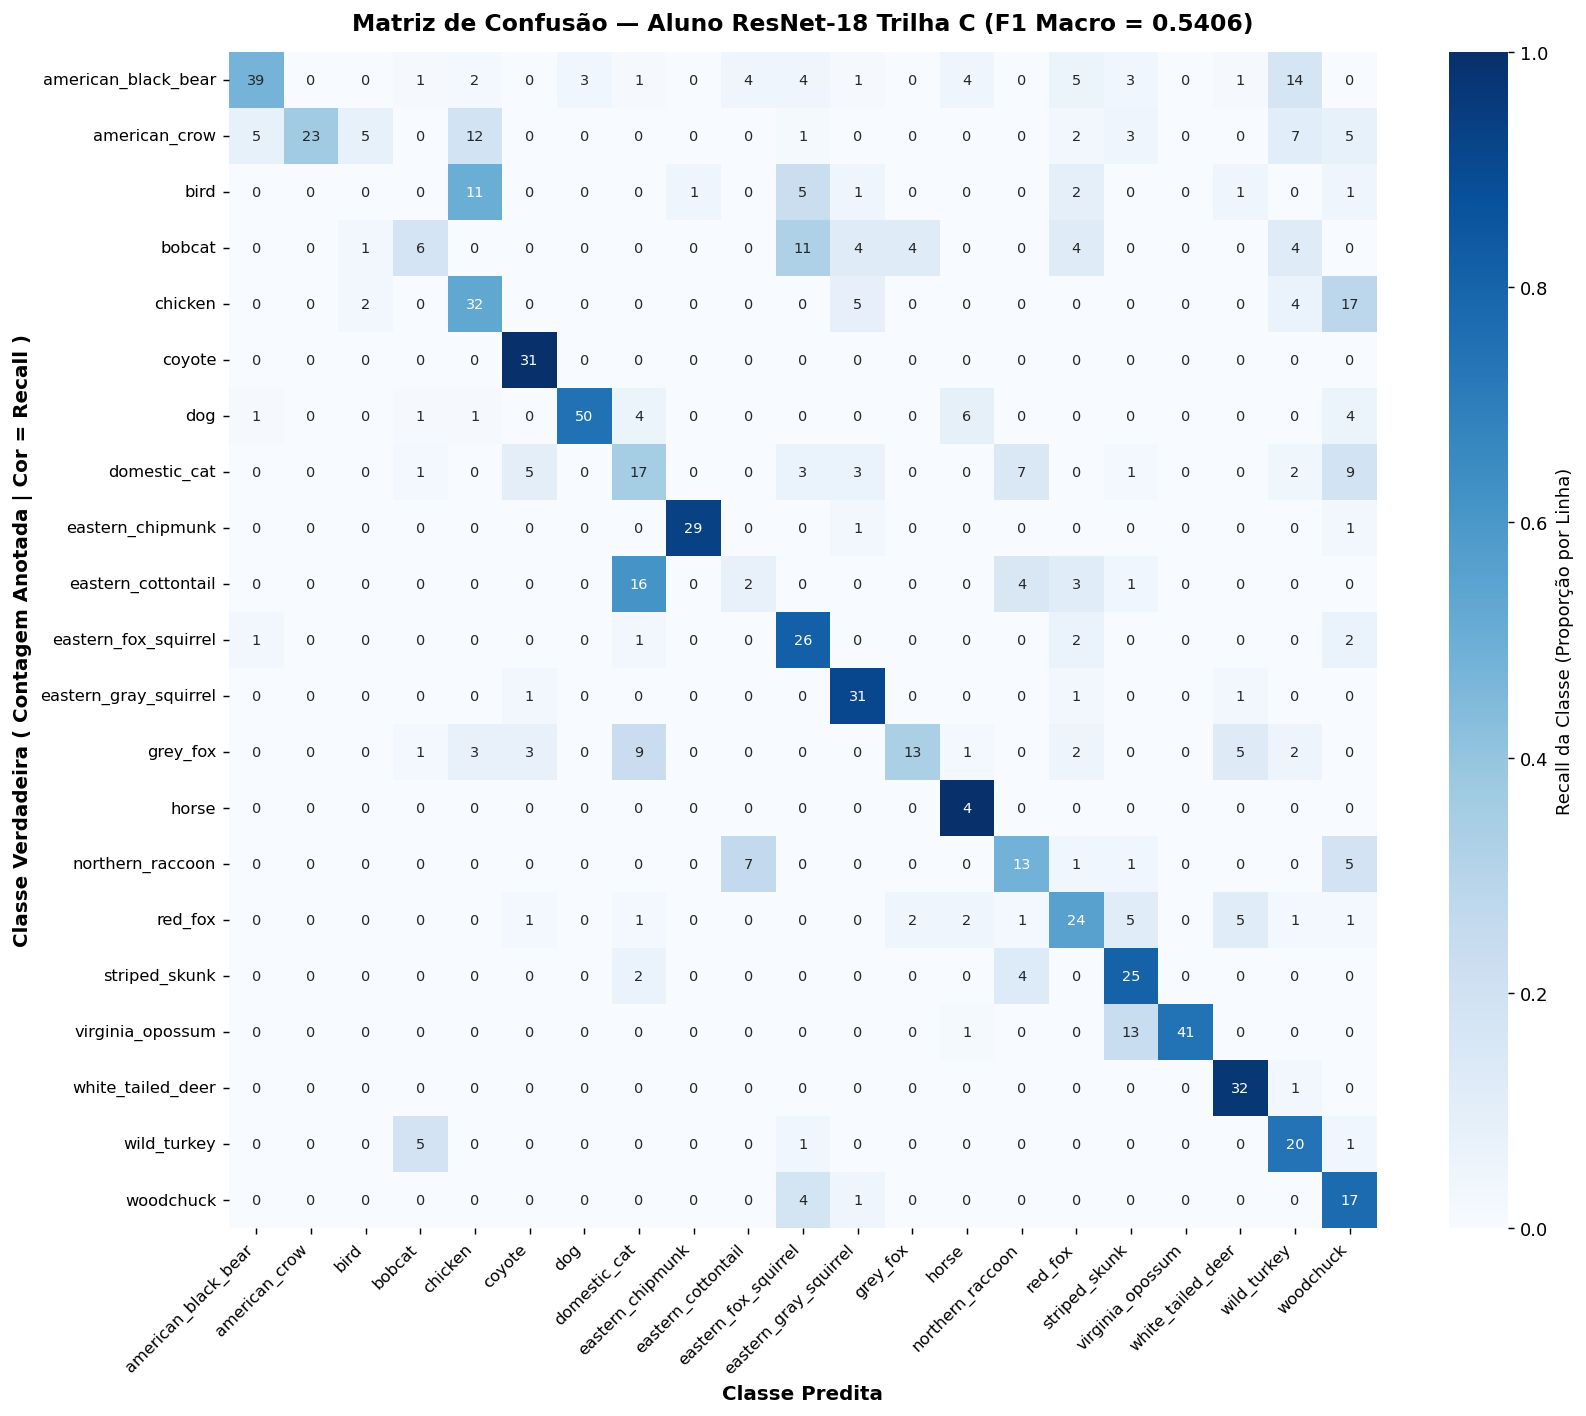

In [12]:
fig, axes, _ = plot_training_curves(
    history=ablation_results["hist_c2"],
    title_prefix="Parte 1 (Trilha C) — Aluno ResNet-18 Selecionado no val",
    show=True,
)

fig, ax = plot_confusion_matrix(
    cm=ablation_results["test_c2"]["confusion_matrix"],
    class_names=teacher_data["class_names"],
    title=f"Matriz de Confusão — Aluno ResNet-18 Trilha C (F1 Macro = {ablation_results['test_c2']['f1_macro']:.4f})",
    show=True,
)

### Em Quais Classes o Aluno Supera o Professor?

O Aluno supera o Professor Zero-Shot em **19 das 21 classes**, destacando-se:
- `eastern_chipmunk`: sobe de `0,050` no Professor para `0,967` no Aluno (+0,917 no F1)
- `dog`: sobe de `0,222` para `0,782` (+0,560)
- `chicken`: sobe de `0,077` para `0,589` (+0,512)
- `coyote`: sobe de `0,476` para `0,861` (+0,385)
- `eastern_gray_squirrel`: sobe de `0,295` para `0,674` (+0,379)
- `grey_fox`: sobe de `0,049` para `0,400` (+0,351)

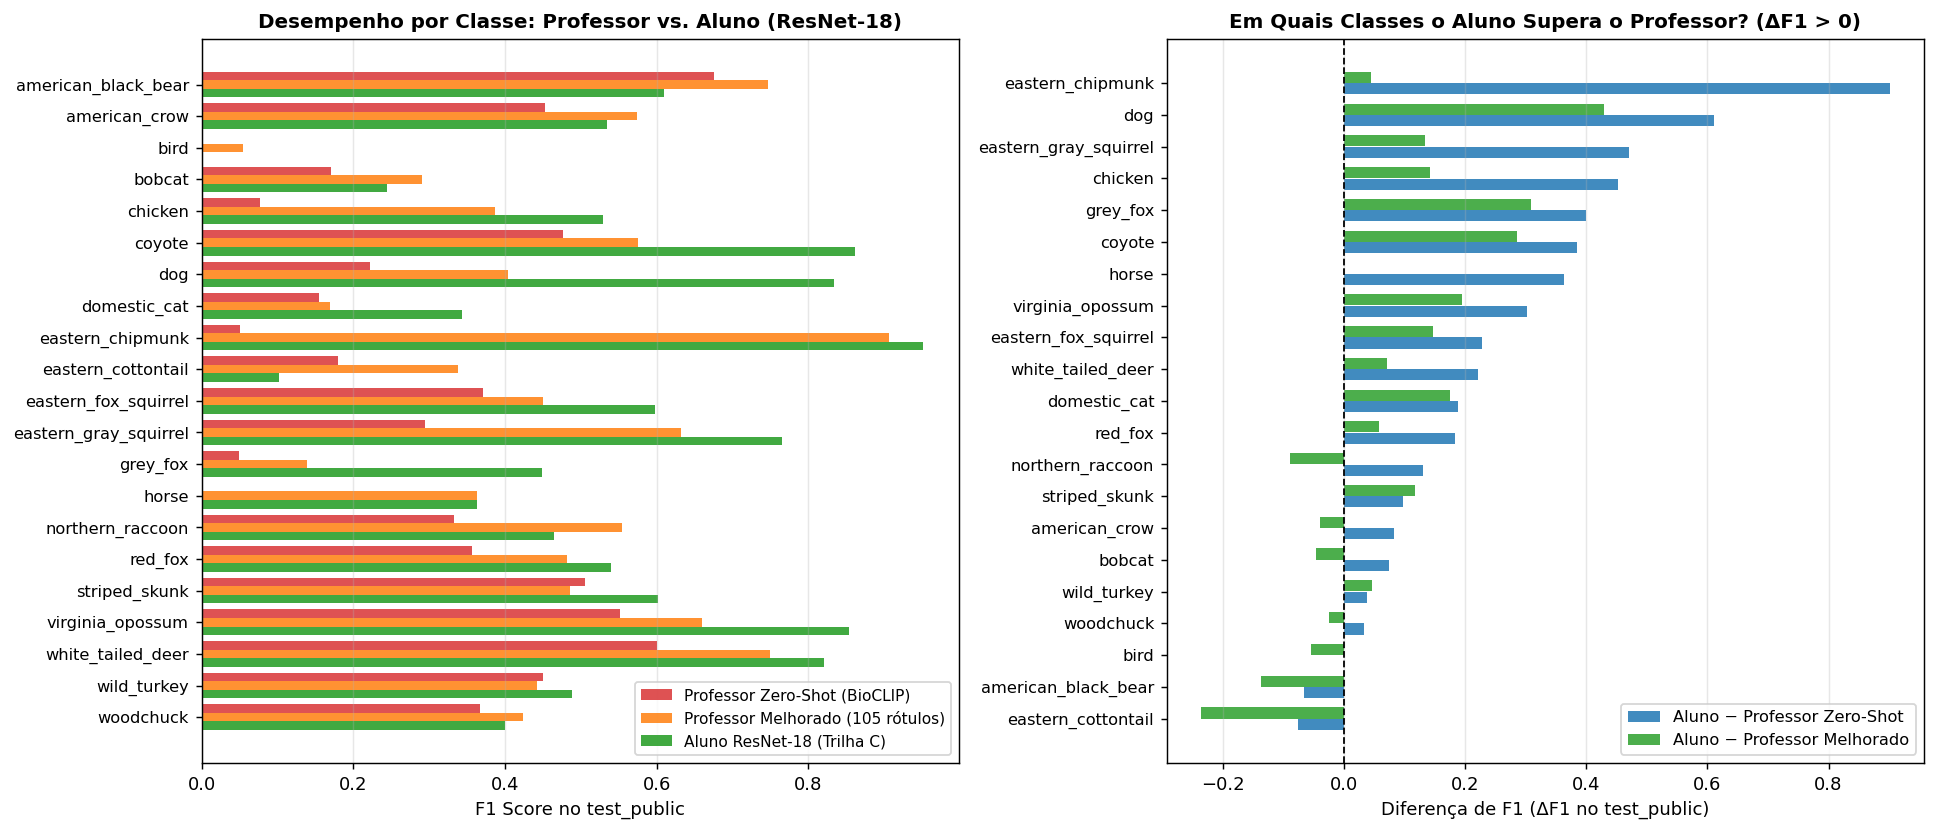

,idx,label,f1_piso_0b,f1_prof_zeroshot,f1_prof_melhorado,f1_aluno_resnet18,ganho_aluno_vs_prof_zs,ganho_aluno_vs_prof_imp,ganho_aluno_vs_piso
0,8,eastern_chipmunk,0.966667,0.050000,0.906250,0.950820,0.900820,0.044570,-0.015847
1,6,dog,0.731707,0.222222,0.404494,0.833333,0.611111,0.428839,0.101626
2,11,eastern_gray_squirrel,0.752941,0.294737,0.632653,0.765432,0.470695,0.132779,0.012491
3,4,chicken,0.480769,0.076923,0.387097,0.528926,0.452003,0.141829,0.048156
4,12,grey_fox,0.270270,0.048780,0.139535,0.448276,0.399495,0.308741,0.178006
5,5,coyote,0.468085,0.476190,0.575758,0.861111,0.384921,0.285354,0.393026
6,13,horse,0.333333,0.000000,0.363636,0.363636,0.363636,0.000000,0.030303
7,17,virginia_opossum,0.775510,0.551724,0.660194,0.854167,0.302443,0.193972,0.078656
8,10,eastern_fox_squirrel,0.476190,0.370370,0.450704,0.597701,0.227331,0.146997,0.121511
9,18,white_tailed_deer,0.640000,0.600000,0.750000,0.820513,0.220513,0.070513,0.180513


In [13]:
fig, axes, df_comp = plot_student_vs_teacher_per_class(
    class_names=teacher_data["class_names"],
    f1_piso=floor_results["test_metrics_b"]["per_class_f1"],
    f1_teacher_zs=zs_eval["per_class_f1_zero_shot"],
    f1_teacher_imp=teacher_data["imp_teacher"]["test_per_class_f1"],
    f1_student=ablation_results["test_c2"]["per_class_f1"],
    show=True,
)
display(df_comp.sort_values("ganho_aluno_vs_prof_zs", ascending=False).reset_index(drop=True))

## Parte 2 — A Curva de Orçamento
Avaliamos o Piso Supervisionado (`ResNet-18`) e o Aluno da Trilha C nos orçamentos de **1, 5 e 20 rótulos por classe**:
- No orçamento de 5 rótulos: **3 seeds (`42`, `123`, `999`)** para média $\pm$ desvio padrão.
- Gráfico semi-log com barras de erro, linha do Professor Zero-Shot (`0,3017`) e Teto (`0,6860`).
- Exportação da tabela oficial para `curva_orcamento.csv`.

In [14]:
df_curva, piso_b5_per_class, aluno_b5_per_class, _ = run_budget_curve(
    data_dir="data",
    checkpoints_dir="checkpoints",
    seeds_b5=[42, 123, 999],
    seed_other=SEED,
    device=device,
    rodar_novamente=False,
    verbose=True,
)
print("=== Tabela Oficial: curva_orcamento.csv ===")
display(df_curva)

✓ Carregando predições e embeddings do Professor (BioCLIP) em cache: checkpoints\bioclip_teacher_outputs.pt
✓ Carregando Piso B=1 Seed=42: checkpoints\part0b_resnet18_b1_s42.pt
✓ Carregando Aluno Trilha C B=1 Seed=42: checkpoints\part2_student_trilha_c_b1_s42.pt
✓ Carregando Piso B=5 Seed=42: checkpoints\part0b_resnet18_b5_s42.pt
✓ Carregando Aluno Trilha C B=5 Seed=42: checkpoints\part2_student_trilha_c_b5_s42.pt
✓ Carregando Piso B=5 Seed=123: checkpoints\part0b_resnet18_b5_s123.pt
✓ Carregando Aluno Trilha C B=5 Seed=123: checkpoints\part2_student_trilha_c_b5_s123.pt
✓ Carregando Piso B=5 Seed=999: checkpoints\part0b_resnet18_b5_s999.pt
✓ Carregando Aluno Trilha C B=5 Seed=999: checkpoints\part2_student_trilha_c_b5_s999.pt
✓ Carregando Piso B=20 Seed=42: checkpoints\part0b_resnet18_b20_s42.pt
✓ Carregando Aluno Trilha C B=20 Seed=42: checkpoints\part2_student_trilha_c_b20_s42.pt
=== Tabela Oficial: curva_orcamento.csv ===


,metodo,orcamento,seed,f1_macro,acuracia
0,professor_bioclip_zeroshot,0,42,0.3017,0.3539
1,piso_resnet18,1,42,0.1687,0.2182
2,trilha_c_aluno_resnet18,1,42,0.3797,0.4205
3,piso_resnet18,5,42,0.4639,0.5166
4,trilha_c_aluno_resnet18,5,42,0.5406,0.5857
5,piso_resnet18,5,123,0.4569,0.4846
6,trilha_c_aluno_resnet18,5,123,0.5162,0.5746
7,piso_resnet18,5,999,0.4272,0.4661
8,trilha_c_aluno_resnet18,5,999,0.5033,0.5499
9,piso_resnet18,20,42,0.5984,0.6510


### Gráfico Oficial da Curva de Orçamento (Escala Logarítmica)
Geramos dinamicamente o gráfico oficial com as curvas do Piso e do Aluno, acompanhadas das barras de erro nas 3 seeds do orçamento 5, e exibimos a tabela agregada.

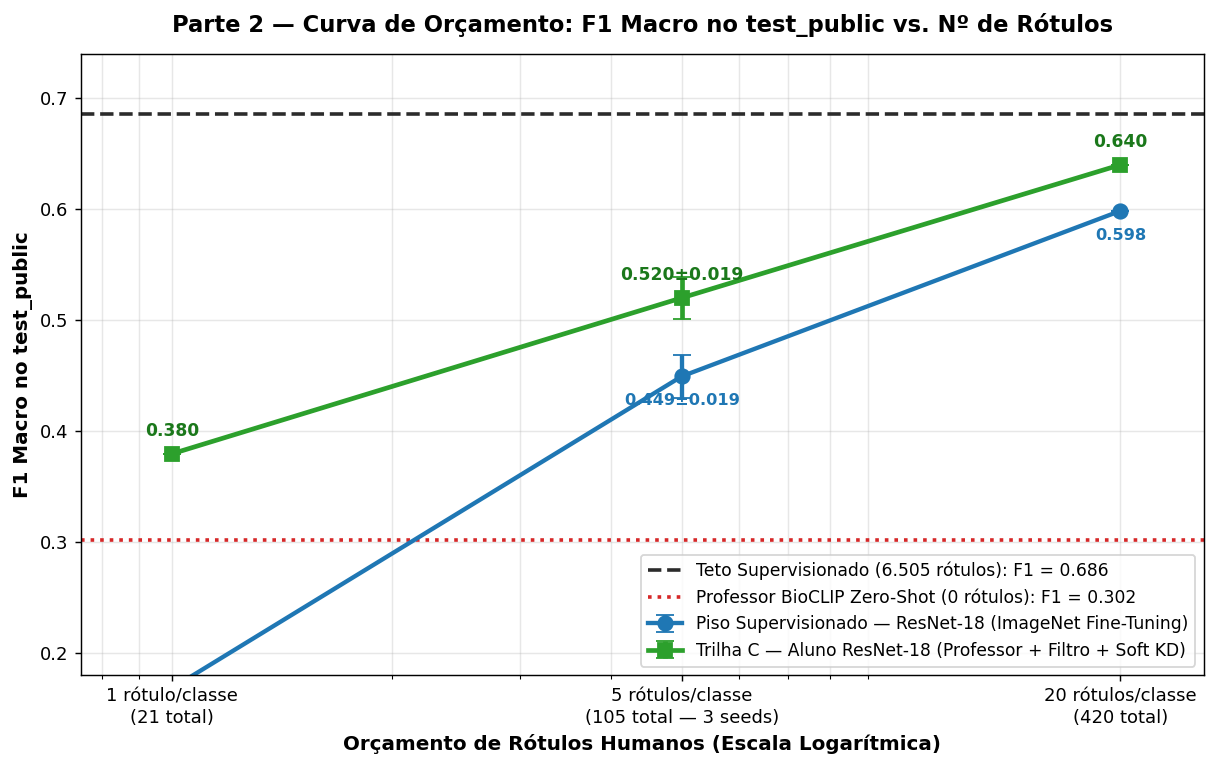

,Orçamento (por classe),Total de Rótulos,Seeds,Piso F1 Macro (test_public),Aluno Trilha C F1 Macro (test_public),Ganho ΔF1 Macro (Aluno − Piso),Piso Acurácia,Aluno Trilha C Acurácia
0,1,21,42,0.1687,0.3797,+0.2110,0.2182,0.4205
1,5,105,"42, 123, 999",0.4493 ± 0.0195,0.5200 ± 0.0189,+0.0707,0.4891 ± 0.0255,0.5701 ± 0.0183
2,20,420,42,0.5984,0.6399,+0.0415,0.6510,0.6856


In [15]:
fig, ax, df_agg = plot_budget_curve(
    df_curva=df_curva,
    teacher_zs_f1=0.3017,
    ceiling_f1=0.6860,
    show=True,
)
display(df_agg)

#### Análise da Dinâmica ao Longo dos Três Orçamentos:
1. **$B = 1$ rótulo/classe (21 imagens):** O piso colapsa em `0,1687` (overfitting imediato em 1 imagem). O Aluno salta para **`0,3797`** (ganho de **`+0,2110` no F1** e **+20,23 pp de acurácia**), superando inclusive o próprio Professor Zero-Shot (`0,3017`).
2. **$B = 5$ rótulos/classe (105 imagens, 3 seeds):** O piso atinge `0,4493 ± 0,0195`, enquanto o Aluno alcança **`0,5200 ± 0,0189`** (ganho médio de **`+0,0707` no F1** e **+8,10 pp de acurácia**).
3. **$B = 20$ rótulos/classe (420 imagens):** O piso atinge `0,5984` e o Aluno chega a **`0,6399`** de F1 Macro e **`68,56%` de acurácia**, ficando a apenas **$0,046$ do teto de 6.505 rótulos (`0,6860`)** com apenas $6,4\%$ dos dados rotulados!

### Quebra do Ganho por Classe no Orçamento de 5 Rótulos

> **Exigência do Enunciado:** *"Quebrem o ganho por classe no orçamento de 5: quais classes ganharam mais e quais não ganharam nada?"*

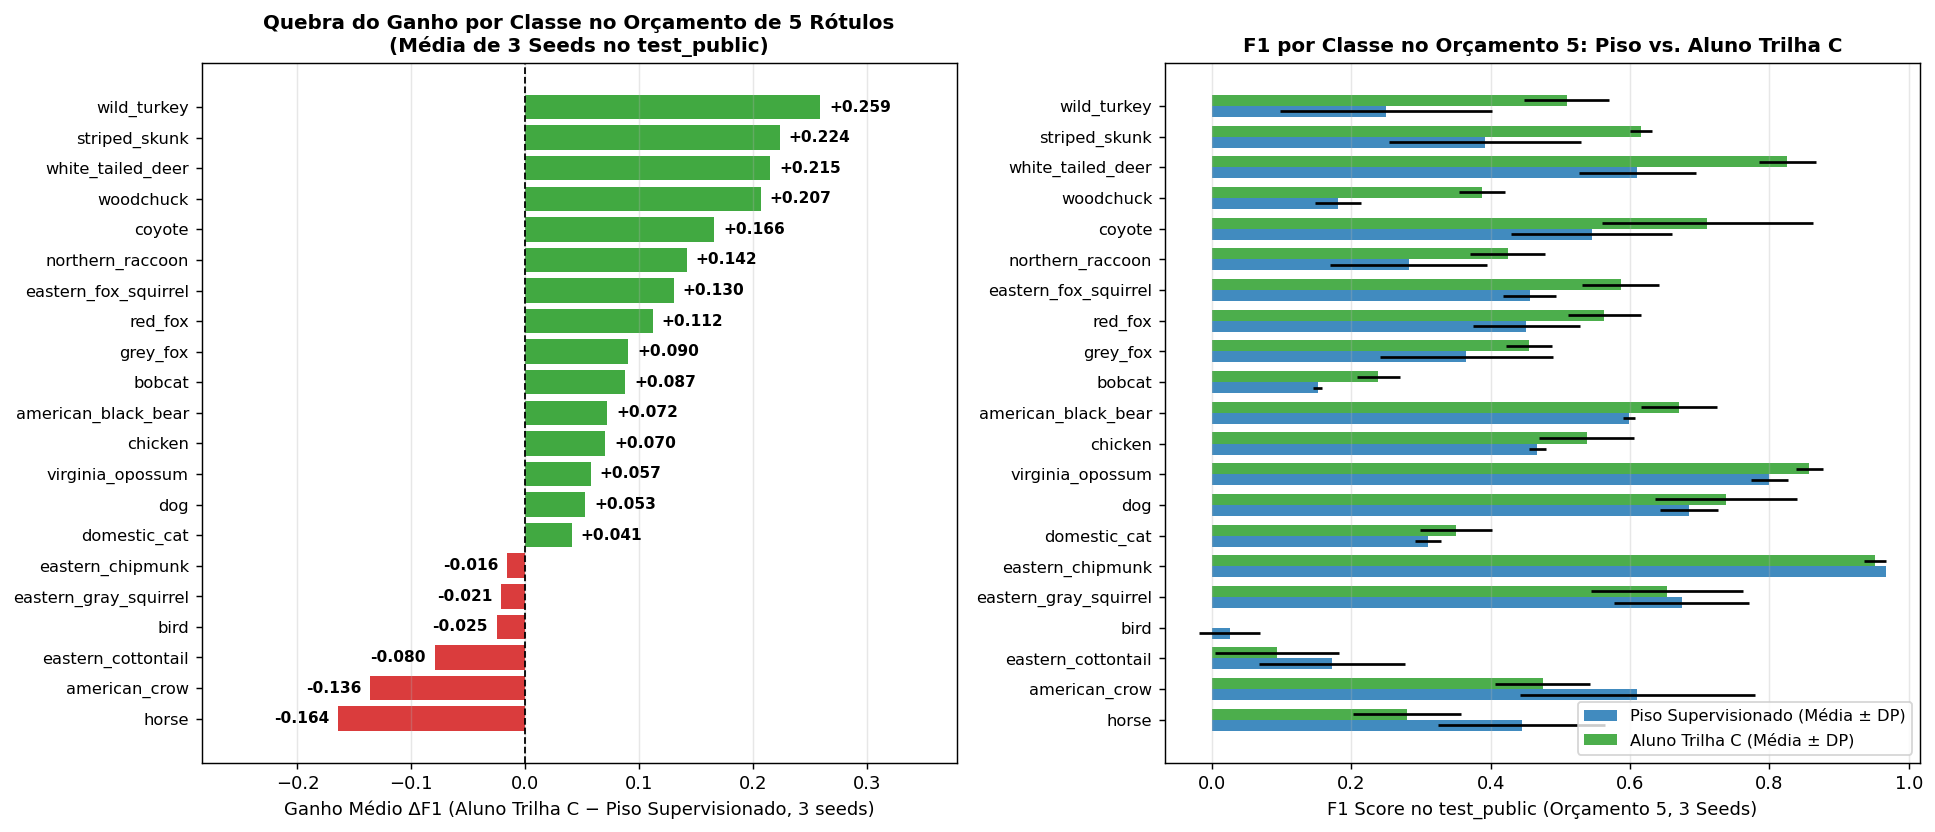

,label,test_support,piso_f1_mean_3seeds,aluno_f1_mean_3seeds,ganho_f1_mean
0,wild_turkey,27,0.249811,0.508755,0.258945
1,striped_skunk,31,0.391683,0.615196,0.223513
2,white_tailed_deer,33,0.610485,0.825604,0.215120
3,woodchuck,22,0.180683,0.387519,0.206837
4,coyote,31,0.544808,0.710771,0.165963
5,northern_raccoon,27,0.282251,0.424122,0.141871
6,eastern_fox_squirrel,32,0.455985,0.586437,0.130452
7,red_fox,43,0.451166,0.563006,0.111840
8,grey_fox,39,0.365045,0.455244,0.090199
9,bobcat,34,0.151412,0.238898,0.087486


In [16]:
fig, axes, df_gain_b5 = plot_per_class_gain_budget5(
    class_names=teacher_data["class_names"],
    piso_b5_per_class_list=piso_b5_per_class,
    aluno_b5_per_class_list=aluno_b5_per_class,
    data_dir="data",
    show=True,
)
display(df_gain_b5[["label", "test_support", "piso_f1_mean_3seeds", "aluno_f1_mean_3seeds", "ganho_f1_mean"]])

## Parte 3 — Galeria de Falhas e Atalhos (Saliência e Grad-CAM)
Analisamos as regiões de atenção espacial do nosso melhor modelo (**Aluno ResNet-18 da Trilha C**, `part2_student_trilha_c_b5_s42.pt`) utilizando **Grad-CAM** na última camada convolucional (`layer4`) sobre imagens fixas do `test_public`.

### Galeria de 3 Falhas no `test_public`
Selecionamos 3 IDs fixos de falhas reais (`expected_correct=False`) para inspecionar imagem original, classe verdadeira, predição com confiança e mapa de saliência Grad-CAM.

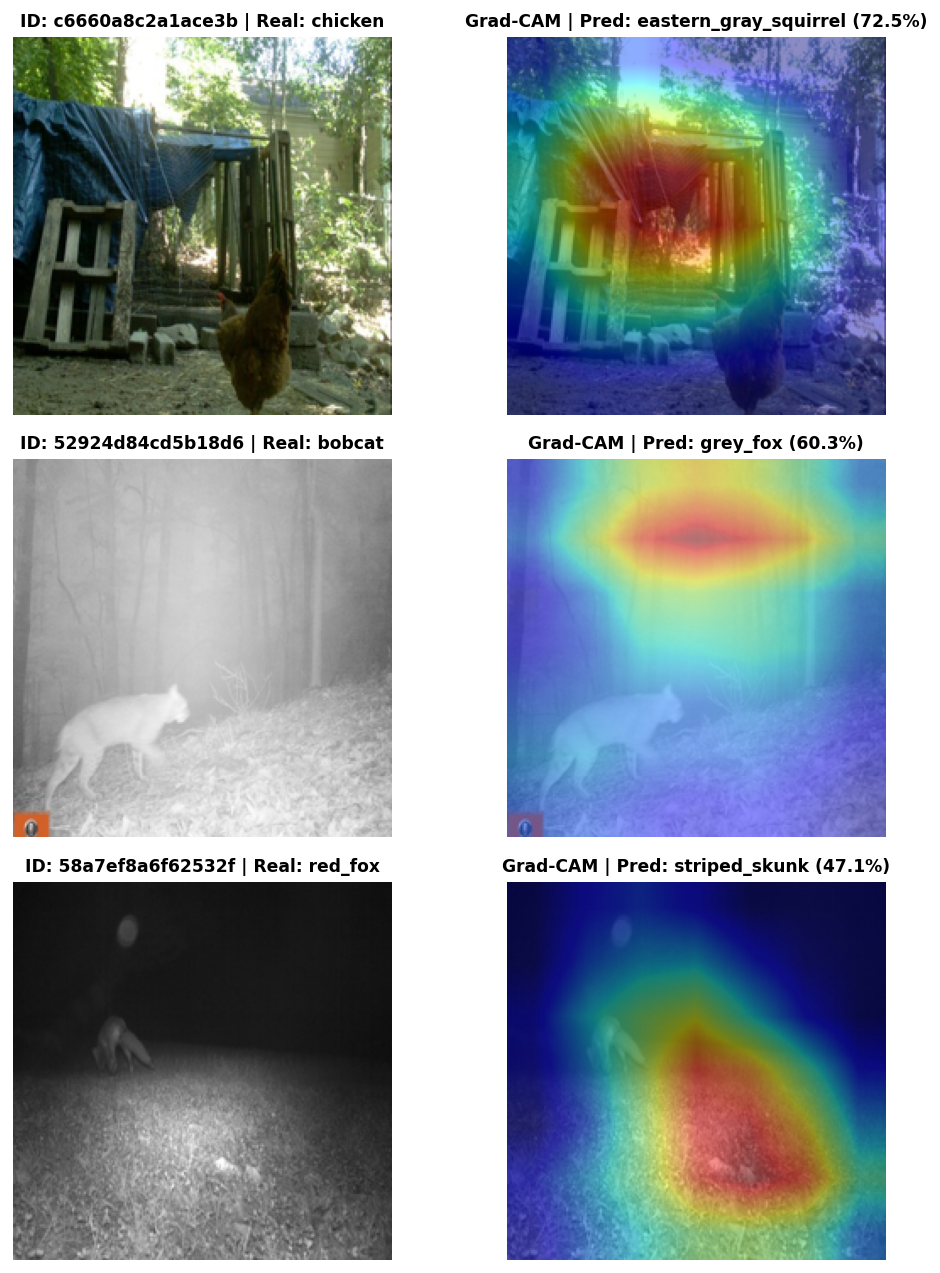

,image_id,true_label,pred_label,confidence,correct
0,c6660a8c2a1ace3b,chicken,eastern_gray_squirrel,0.7245,False
1,52924d84cd5b18d6,bobcat,grey_fox,0.6030,False
2,58a7ef8a6f62532f,red_fox,striped_skunk,0.4708,False


In [17]:
FAILURE_IDS = [
    "c6660a8c2a1ace3b",
    "52924d84cd5b18d6",
    "58a7ef8a6f62532f",
]

fig, axes, df_failures = plot_gradcam_gallery(
    model=ablation_results["student_c2"],
    image_ids=FAILURE_IDS,
    data_dir="data",
    split="test_public",
    expected_correct=False,
    show=True,
)
display(df_failures)

#### Diagnóstico das 3 Falhas:
1. **ID `c6660a8c2a1ace3b` (`Real: chicken` $\rightarrow$ `Pred: eastern_gray_squirrel`, confiança `72,5%`) — Atalho Espúrio de Fundo (Foco no Cenário e Ignorando o Animal):**
   - **Diagnóstico:** Há uma galinha marrom (`chicken`) grande e perfeitamente visível no primeiro plano inferior direito, mas o mapa de Grad-CAM deixa o corpo da galinha completamente frio (azul escuro) e concentra toda a ativação vermelha **na estrutura de madeira, palete e lona azul ao fundo**, associando incorretamente esses objetos de quintal à classe `eastern_gray_squirrel`.
2. **ID `52924d84cd5b18d6` (`Real: bobcat` $\rightarrow$ `Pred: grey_fox`, confiança `60,3%`) — Captura Noturna em Infravermelho (IR) + Foco no Fundo Florestal:**
   - **Diagnóstico:** O lince-pardo (`bobcat`) caminha no canto inferior esquerdo sob forte iluminação infravermelha que lava a textura manchada de sua pelagem e cria uma névoa clara entre os troncos ao fundo. O Grad-CAM deixa o corpo do animal frio (azul) e foca **no clarão difuso entre as árvores na parte superior do quadro**, confundindo a cena noturna com o habitat de `grey_fox`.
3. **ID `58a7ef8a6f62532f` (`Real: red_fox` $\rightarrow$ `Pred: striped_skunk`, confiança `47,1%`) — Animal Distante no Escuro + Reflexo do Flash IR no Solo:**
   - **Diagnóstico:** A raposa-vermelha (`red_fox`) está muito pequena e distante na penumbra superior esquerda, enquanto o flash infravermelho estoura o brilho do cascalho no centro-direita do chão. O Grad-CAM foca **na mancha branca brilhante do solo iluminado pelo flash IR** em contraste com o fundo preto, confundindo esse padrão de alto contraste preto/branco com a listra dorsal de um gambá (`striped_skunk`).

### Galeria de 5 Acertos no `test_public`
Selecionamos 5 IDs fixos de acertos reais (`expected_correct=True`) para avaliar quando o modelo acerta pelas **razões certas** (foco anatômico no espécime) e quando acerta pelas **razões erradas** (atalho espúrio de fundo/câmera).

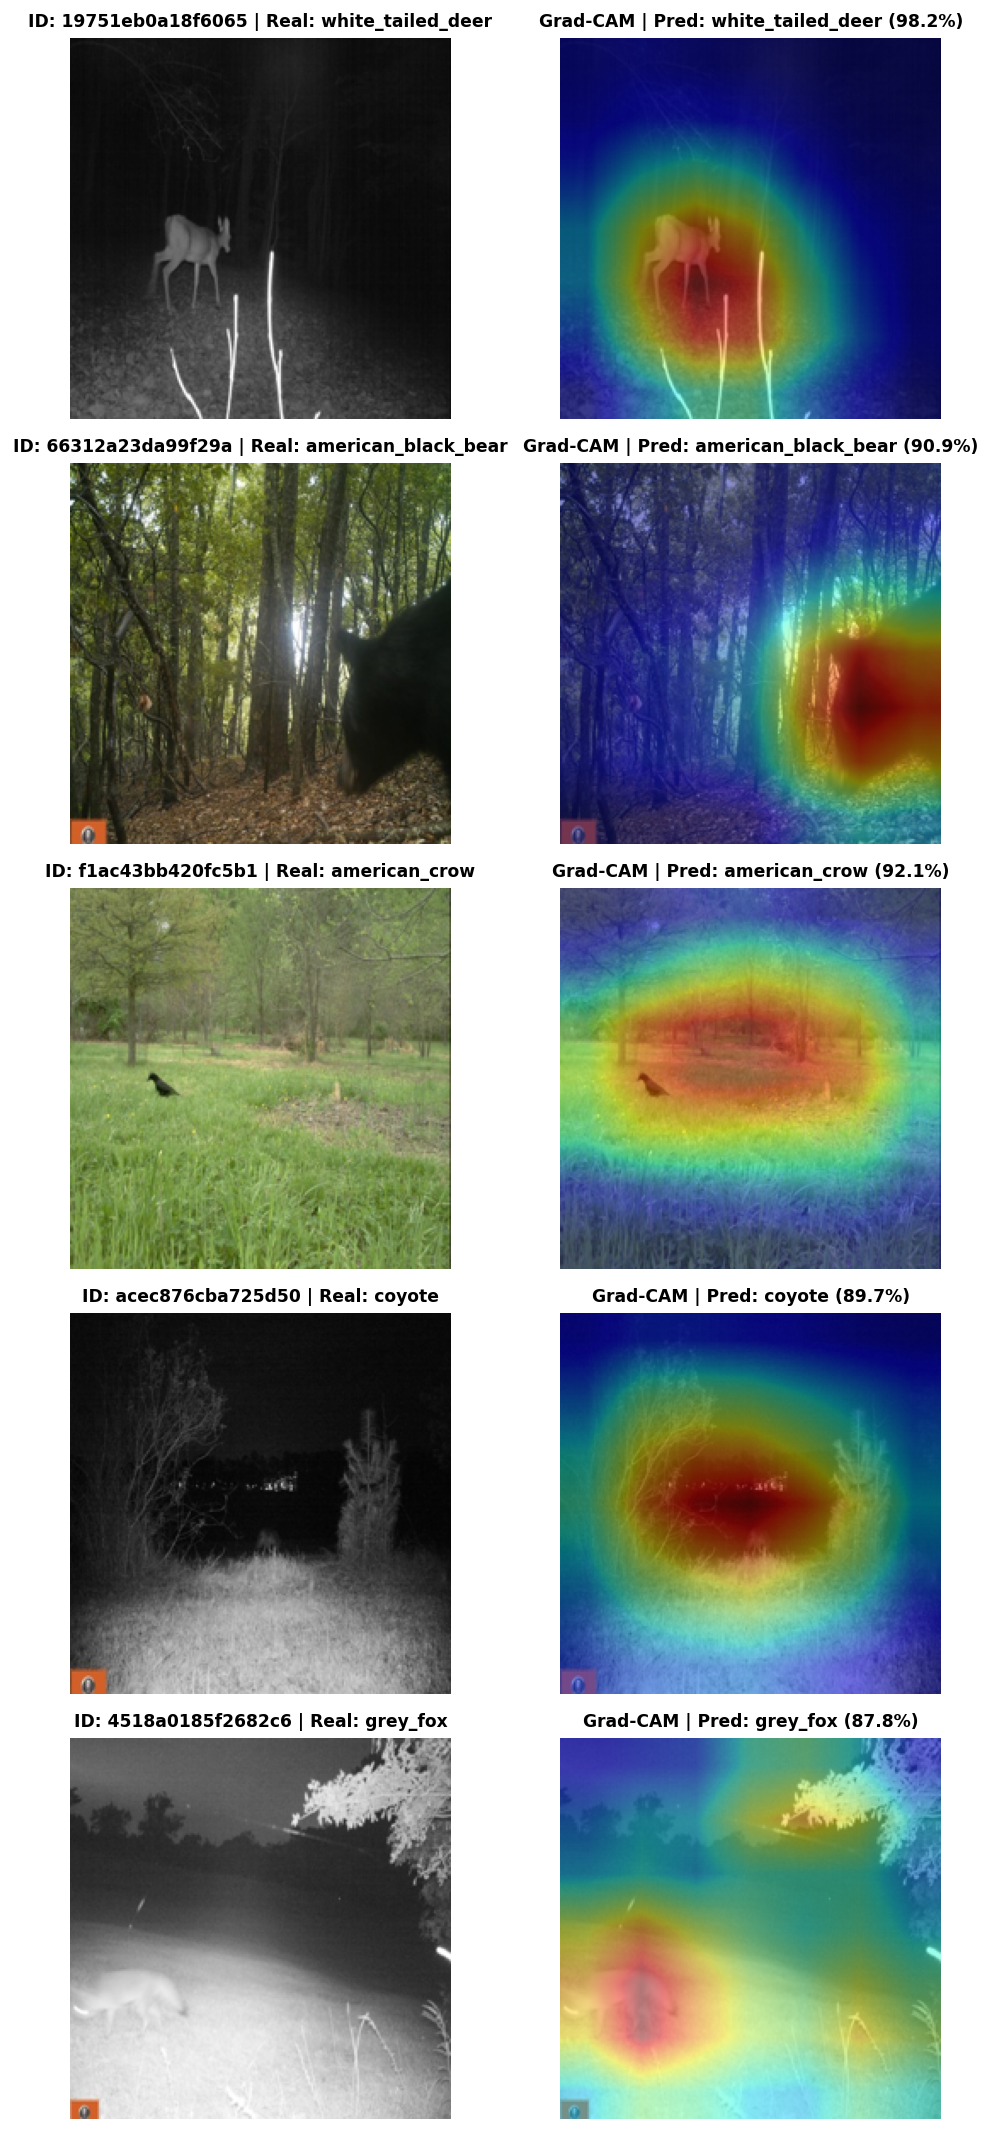

,image_id,true_label,pred_label,confidence,correct
0,19751eb0a18f6065,white_tailed_deer,white_tailed_deer,0.9821,True
1,66312a23da99f29a,american_black_bear,american_black_bear,0.9095,True
2,f1ac43bb420fc5b1,american_crow,american_crow,0.9206,True
3,acec876cba725d50,coyote,coyote,0.8965,True
4,4518a0185f2682c6,grey_fox,grey_fox,0.8776,True


In [18]:
SUCCESS_IDS = [
    "19751eb0a18f6065",
    "66312a23da99f29a",
    "f1ac43bb420fc5b1",
    "acec876cba725d50",
    "4518a0185f2682c6",
]

fig, axes, df_successes = plot_gradcam_gallery(
    model=ablation_results["student_c2"],
    image_ids=SUCCESS_IDS,
    data_dir="data",
    split="test_public",
    expected_correct=True,
    show=True,
)
display(df_successes)

#### Diagnóstico dos 5 Acertos (Foco no Animal vs. Atalho de Fundo):
1. **ID `19751eb0a18f6065` (`white_tailed_deer`, confiança `98,2%`) — Acertou pela Razão Certa (Foco no Animal):**
   - **Diagnóstico:** Apesar de ser uma captura noturna em infravermelho, o mapa de Grad-CAM está **integralmente centrado sobre o tronco, pescoço e cabeça do cervo**, ignorando a floresta escura e os galhos secos em primeiro plano.
2. **ID `66312a23da99f29a` (`american_black_bear`, confiança `91,0%`) — Acertou pela Razão Certa (Foco no Animal):**
   - **Diagnóstico:** Mesmo com o urso posicionado na extremidade direita do quadro em uma floresta densa e iluminada, o Grad-CAM ignora todas as árvores à esquerda e **concentra a ativação exclusivamente sobre o focinho, orelha e pelagem preta do urso**.
3. **ID `f1ac43bb420fc5b1` (`american_crow`, confiança `92,1%`) — Acertou por Contexto/Atalho de Cenário (Clareira Aberta):**
   - **Diagnóstico:** O corvo preto (`american_crow`) está perfeitamente visível pousado no gramado à esquerda, mas o pico principal do Grad-CAM espalha-se **pela clareira aberta e linha de árvores ao fundo no centro-direita**, tocando apenas perifericamente a ave, mostrando que a rede utilizou fortemente o cenário de campo aberto daquela câmera para confirmar a classe.
4. **ID `acec876cba725d50` (`coyote`, confiança `89,7%`) — Acertou pela Razão Errada (Atalho de Horizonte/Câmera Noturna):**
   - **Diagnóstico:** Na captura noturna, o coiote está na penumbra central, mas a rede prediz `coyote` com 89,7% de confiança focando **na linha do horizonte com luzes ao fundo e na silhueta dos arbustos laterais**, características fixas daquela estação de câmera.
5. **ID `4518a0185f2682c6` (`grey_fox`, confiança `87,8%`) — Acerto Misto (Corpo do Animal + Atalho Secundário de Folhagem):**
   - **Diagnóstico:** O pico principal do Grad-CAM localiza corretamente **o corpo e a cauda da raposa-cinzenta (`grey_fox`)** à esquerda, mas observa-se um foco secundário no canto superior direito sobre os ramos iluminados pelo infravermelho, indicando uso combinado de morfologia do animal e contexto da câmera.